# **Proyecto de Sueño — Sleep-EDF (Sleep-Cassette)**

Este notebook conserva mi forma de trabajar: **primero exploro el primer registro**, después realizo el preprocesamiento y verifico cómo quedaron las señales, y finalmente proceso todos los registros y guardo los archivos para el modelo.

**Cambios:** usar **EEG Fpz-Cz, EEG Pz-Oz y EOG horizontal** (sin EMG submental), incluir **Movement time (M)** como sexta categoría y conservar el recorte de 30 minutos de vigilia antes/después del sueño. Las etapas 3 y 4 siguen agrupadas como N3.

Los PSG e hipnogramas `.edf` se leen **directamente desde Google Drive** usando la misma ruta del código original. No se descargan de nuevo.

## **1. Librerías y conexión a Google Drive**

Conectamos Drive y localizamos los archivos EDF que ya están allí.

In [2]:
%pip install -q mne jedi

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.


In [3]:
# Si MNE no está instalado en esta sesión, ejecutar una vez:
# %pip install -q mne jedi

from google.colab import drive
from pathlib import Path
from tqdm.auto import tqdm
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

drive.mount("/content/drive")

# Misma ruta de los PSG e hipnogramas en el notebook original
ruta_SleepCassette = Path(
    "/content/drive/MyDrive/SleepEDFx/physionet.org/files/"
    "sleep-edfx/1.0.0/sleep-cassette"
)
print("¿Existe la carpeta?", ruta_SleepCassette.exists())

Mounted at /content/drive
¿Existe la carpeta? True


## **2. Encontrar y emparejar los PSG y los hipnogramas**

Cada PSG se empareja con su hipnograma por los **primeros seis caracteres** del nombre, como en mi código original.

In [4]:
psg_files = sorted(ruta_SleepCassette.glob("*-PSG.edf"))
hyp_files = sorted(ruta_SleepCassette.glob("*-Hypnogram.edf"))

print("PSG encontrados:", len(psg_files))
print("Hipnogramas encontrados:", len(hyp_files))

if not psg_files or not hyp_files:
    raise FileNotFoundError("No se encontraron los EDF. Revisar ruta_SleepCassette.")

pares = []
for psg in psg_files:
    id_registro = psg.name[:6]
    hyp = [h for h in hyp_files if h.name.startswith(id_registro)]

    if len(hyp) == 1:
        pares.append((psg, hyp[0]))
    else:
        print("Revisar registro:", id_registro, "Hipnogramas:", len(hyp))

print("Registros emparejados:", len(pares))
for psg, hyp in pares[:5]:
    print(psg.name, "<-->", hyp.name)

if not pares:
    raise ValueError("No hay parejas PSG-Hipnograma para procesar.")

PSG encontrados: 153
Hipnogramas encontrados: 153
Registros emparejados: 153
SC4001E0-PSG.edf <--> SC4001EC-Hypnogram.edf
SC4002E0-PSG.edf <--> SC4002EC-Hypnogram.edf
SC4011E0-PSG.edf <--> SC4011EH-Hypnogram.edf
SC4012E0-PSG.edf <--> SC4012EC-Hypnogram.edf
SC4021E0-PSG.edf <--> SC4021EH-Hypnogram.edf


## **3. Canales y etapas del sueño**

Conservo dos EEG y el EOG. **No selecciono el EMG submental.** Los códigos son de 1 a 6; `Sleep stage ?` queda excluido. `Movement time` se identifica como M, aunque no es una etapa fisiológica del sueño.

In [5]:
# Canales que utilizaremos (sin EMG)
canales = ["Fpz-Cz", "Pz-Oz", "horizontal"]

# Etapas que permiten identificar el período de sueño
etapas_sueno = [
    "Sleep stage 1", "Sleep stage 2", "Sleep stage 3",
    "Sleep stage 4", "Sleep stage R"
]

# Convertir las anotaciones en códigos numéricos
annotation_desc_2_event_id = {
    "Sleep stage W": 1,
    "Sleep stage 1": 2,
    "Sleep stage 2": 3,
    "Sleep stage 3": 4,
    "Sleep stage 4": 4,
    "Sleep stage R": 5,
    "Movement time": 6
}

STAGE_NAMES = {1: "W", 2: "N1", 3: "N2", 4: "N3", 5: "REM", 6: "M"}
event_id = {"W": 1, "N1": 2, "N2": 3, "N3": 4, "REM": 5, "M": 6}

print("Canales seleccionados:", canales)
print("Clases:", STAGE_NAMES)

Canales seleccionados: ['Fpz-Cz', 'Pz-Oz', 'horizontal']
Clases: {1: 'W', 2: 'N1', 3: 'N2', 4: 'N3', 5: 'REM', 6: 'M'}


# **4. Exploración del primer registro ANTES del preprocesamiento**

Igual que en mi notebook original, primero verifico las señales, las anotaciones, el hipnograma y la distribución de etapas del primer registro **sin aplicar todavía el recorte de vigilia**.

### **4.1. Leer el PSG y observar las señales originales**

In [6]:
# Primera pareja de archivos
psg_prueba, hyp_prueba = pares[0]

raw_prueba = mne.io.read_raw_edf(
    psg_prueba,
    infer_types=True,
    preload=False,
    verbose="ERROR"
)

print("Registro:", psg_prueba.name)
print("Canales originales:", raw_prueba.ch_names)
print("Frecuencia de muestreo (Hz):", raw_prueba.info["sfreq"])
print("Duración (h):", round(raw_prueba.n_times / raw_prueba.info["sfreq"] / 3600, 2))

# Conservar únicamente los canales que usaremos
raw_prueba.pick(canales)
print("Canales seleccionados:", raw_prueba.ch_names)
print("Tipos:", raw_prueba.get_channel_types())

Registro: SC4001E0-PSG.edf
Canales originales: ['Fpz-Cz', 'Pz-Oz', 'horizontal', 'oro-nasal', 'submental', 'rectal', 'Event marker']
Frecuencia de muestreo (Hz): 100.0
Duración (h): 22.08
Canales seleccionados: ['Fpz-Cz', 'Pz-Oz', 'horizontal']
Tipos: ['eeg', 'eeg', 'eog']


Using matplotlib as 2D backend.
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


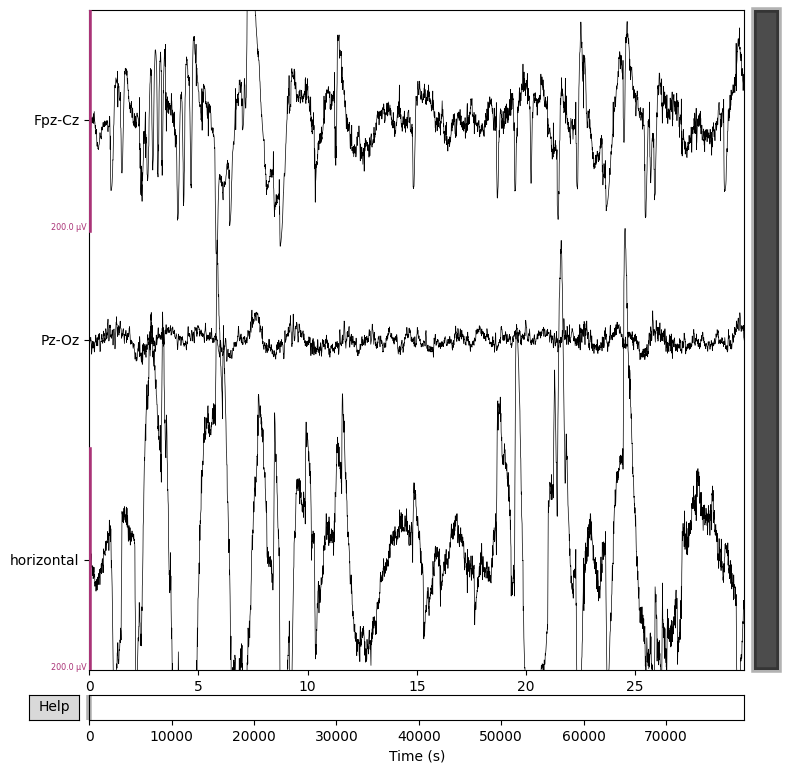

In [7]:
# Visualizar los primeros 30 segundos de las señales seleccionadas
raw_prueba.plot(
    start=0,
    duration=30,
    n_channels=len(canales),
    scalings=dict(eeg=1e-4, eog=1e-4)
);

### **4.2. Leer el hipnograma y revisar sus anotaciones**

Cada anotación trae la etapa, el instante de inicio y la duración.

In [8]:
annot_prueba = mne.read_annotations(hyp_prueba)

print("Hipnograma:", hyp_prueba.name)
print("Número de anotaciones:", len(annot_prueba))

# Mostrar las primeras 10 anotaciones
for i in range(min(10, len(annot_prueba))):
    print(annot_prueba.description[i],
          "| Inicio (s):", annot_prueba.onset[i],
          "| Duración (s):", annot_prueba.duration[i])

# Cuántas anotaciones indican movimiento y cuánto duran
movimientos = annot_prueba.description == "Movement time"
print("\nAnotaciones de Movement time:", movimientos.sum())
if movimientos.any():
    print("Duraciones de movimiento (s):", annot_prueba.duration[movimientos])
    print("Movimientos de al menos 30 s:", np.sum(annot_prueba.duration[movimientos] >= 30))

Hipnograma: SC4001EC-Hypnogram.edf
Número de anotaciones: 154
Sleep stage W | Inicio (s): 0.0 | Duración (s): 30630.0
Sleep stage 1 | Inicio (s): 30630.0 | Duración (s): 120.0
Sleep stage 2 | Inicio (s): 30750.0 | Duración (s): 390.0
Sleep stage 3 | Inicio (s): 31140.0 | Duración (s): 30.0
Sleep stage 2 | Inicio (s): 31170.0 | Duración (s): 30.0
Sleep stage 3 | Inicio (s): 31200.0 | Duración (s): 150.0
Sleep stage 4 | Inicio (s): 31350.0 | Duración (s): 30.0
Sleep stage 3 | Inicio (s): 31380.0 | Duración (s): 60.0
Sleep stage 4 | Inicio (s): 31440.0 | Duración (s): 60.0
Sleep stage 3 | Inicio (s): 31500.0 | Duración (s): 30.0

Anotaciones de Movement time: 0


### **4.3. Construir el hipnograma del primer registro**

Lo dibujamos a partir de las anotaciones, utilizando su **tiempo real** y su duración. Así no desaparecen los intervalos desconocidos ni se comprime artificialmente el eje temporal.

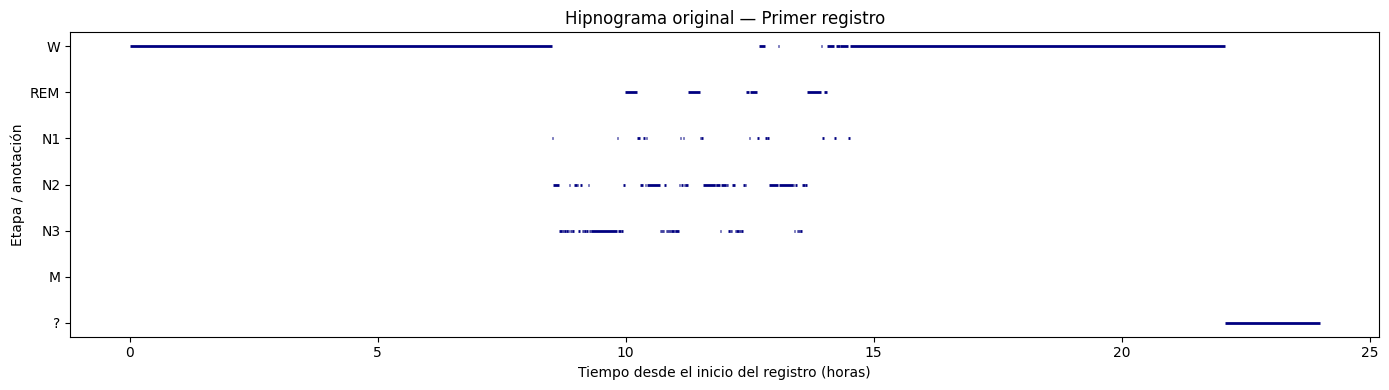

In [9]:
# Nombres de las anotaciones, incluyendo la clase desconocida para verla
nombres_anotaciones = {
    "Sleep stage W": "W",
    "Sleep stage 1": "N1",
    "Sleep stage 2": "N2",
    "Sleep stage 3": "N3",
    "Sleep stage 4": "N3",
    "Sleep stage R": "REM",
    "Movement time": "M",
    "Sleep stage ?": "?"
}

orden = ["W", "REM", "N1", "N2", "N3", "M", "?"]
posiciones = {nombre: i for i, nombre in enumerate(orden)}

fig, ax = plt.subplots(figsize=(14, 4))
for inicio, duracion, descripcion in zip(
    annot_prueba.onset, annot_prueba.duration, annot_prueba.description
):
    if descripcion in nombres_anotaciones:
        etapa = nombres_anotaciones[descripcion]
        ax.hlines(
            posiciones[etapa], inicio / 3600, (inicio + duracion) / 3600,
            color="navy", linewidth=2
        )

ax.set_yticks(range(len(orden)))
ax.set_yticklabels(orden)
ax.invert_yaxis()
ax.set_xlabel("Tiempo desde el inicio del registro (horas)")
ax.set_ylabel("Etapa / anotación")
ax.set_title("Hipnograma original — Primer registro")
plt.tight_layout()
plt.show()

### **4.4. Distribución de las clases del primer registro antes del recorte**

Como en el código original, transformamos las anotaciones en eventos de 30 segundos y contamos cada etapa. **No contamos `Sleep stage ?` como una clase.**

,Etapa,Épocas
0,W,1997
1,N1,58
2,N2,250
3,N3,220
4,REM,125
5,M,0


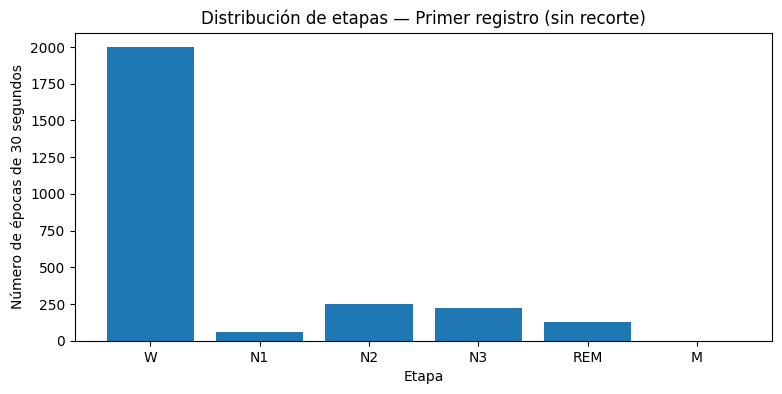

Épocas de movimiento M: 0


In [10]:
raw_prueba.set_annotations(annot_prueba, emit_warning=False)

events_originales, _ = mne.events_from_annotations(
    raw_prueba,
    event_id=annotation_desc_2_event_id,
    chunk_duration=30.0,
    verbose=False
)

# Contar las épocas de cada clase
conteos_originales = np.bincount(events_originales[:, 2], minlength=7)[1:7]

df_original = pd.DataFrame({
    "Etapa": list(STAGE_NAMES.values()),
    "Épocas": conteos_originales
})
display(df_original)

plt.figure(figsize=(9, 4))
plt.bar(df_original["Etapa"], df_original["Épocas"])
plt.title("Distribución de etapas — Primer registro (sin recorte)")
plt.xlabel("Etapa")
plt.ylabel("Número de épocas de 30 segundos")
plt.show()

print("Épocas de movimiento M:", conteos_originales[5])

# **5. Preprocesamiento**

Ahora sí hacemos los mismos pasos que planteé originalmente: **selección de canales → asociación del hipnograma → recorte de vigilia → eventos → épocas de 30 s**.

Conservo la función `preprocess_recording(psg, hyp)` y su salida `X, y`. La uso primero con el primer sujeto para ver el resultado y luego con todos los registros.

In [11]:
def preprocess_recording(psg, hyp):

    # 1. Leer el PSG y seleccionar los tres canales (sin EMG)
    raw = mne.io.read_raw_edf(
        psg,
        infer_types=True,
        preload=False,
        verbose="ERROR"
    )
    raw.pick(canales)
    raw.load_data()

    # 2. Leer el hipnograma
    annot = mne.read_annotations(hyp)

    # 3. Identificar el inicio y el final del sueño
    indices = np.where(np.isin(annot.description, etapas_sueno))[0]
    if len(indices) == 0:
        raise ValueError("No hay etapas de sueño en " + hyp.name)

    inicio_sueno = annot.onset[indices[0]]
    fin_sueno = annot.onset[indices[-1]] + annot.duration[indices[-1]]

    # 4. Conservar hasta 30 minutos de vigilia antes y después
    inicio = max(0, inicio_sueno - 1800)
    fin = min(raw.n_times / raw.info["sfreq"], fin_sueno + 1800)
    annot.crop(inicio, fin)
    raw.set_annotations(annot, emit_warning=False)

    # 5. Generar eventos de 30 segundos
    events, _ = mne.events_from_annotations(
        raw,
        event_id=annotation_desc_2_event_id,
        chunk_duration=30.0,
        verbose=False
    )

    # 6. Segmentar las señales en épocas de 30 segundos
    epochs = mne.Epochs(
        raw,
        events,
        event_id=event_id,
        tmin=0,
        tmax=30 - 1 / raw.info["sfreq"],
        baseline=None,
        preload=True,
        on_missing="ignore",
        verbose=False
    )

    # 7. Obtener señales y etiquetas
    X = epochs.get_data().astype(np.float32)
    y = epochs.events[:, 2].astype(np.int8)

    return X, y

## **6. Ver cómo quedó el PRIMER registro después del preprocesamiento**

Reading 0 ... 7949999  =      0.000 ... 79499.990 secs...
Dimensiones X: (841, 3, 3000)
Dimensiones y: (841,)
Canales: ['Fpz-Cz', 'Pz-Oz', 'horizontal']
Clases presentes: [1 2 3 4 5]
¿Una etiqueta por época? True
¿Sin EMG? True


,Etapa,Antes del recorte,Después del recorte
0,W,1997,188
1,N1,58,58
2,N2,250,250
3,N3,220,220
4,REM,125,125
5,M,0,0


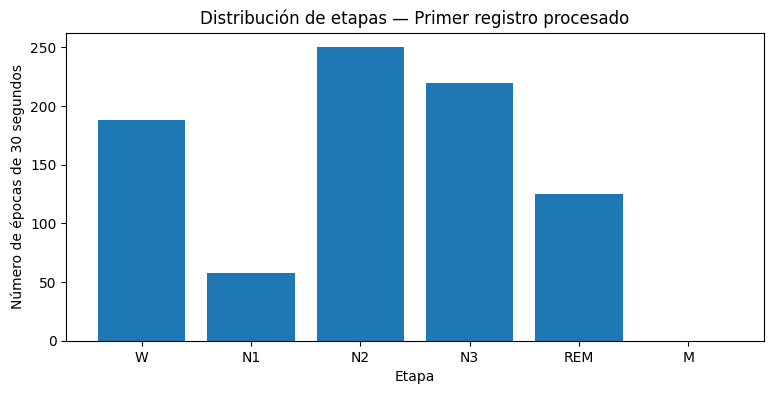

In [12]:
# Probar todo el preprocesamiento solamente con el primer registro
X_prueba, y_prueba = preprocess_recording(psg_prueba, hyp_prueba)

print("Dimensiones X:", X_prueba.shape)
print("Dimensiones y:", y_prueba.shape)
print("Canales:", canales)
print("Clases presentes:", np.unique(y_prueba))
print("¿Una etiqueta por época?", len(X_prueba) == len(y_prueba))
print("¿Sin EMG?", X_prueba.shape[1] == 3)

# Distribución del primer registro ya procesado
conteos_prueba = np.bincount(y_prueba, minlength=7)[1:7]

df_prueba = pd.DataFrame({
    "Etapa": list(STAGE_NAMES.values()),
    "Antes del recorte": conteos_originales,
    "Después del recorte": conteos_prueba
})
display(df_prueba)

plt.figure(figsize=(9, 4))
plt.bar(df_prueba["Etapa"], df_prueba["Después del recorte"])
plt.title("Distribución de etapas — Primer registro procesado")
plt.xlabel("Etapa")
plt.ylabel("Número de épocas de 30 segundos")
plt.show()

### **6.1. Visualizar una época después del preprocesamiento**

Cada una de las tres señales debe tener **3.000 muestras** si la frecuencia es 100 Hz (30 segundos).

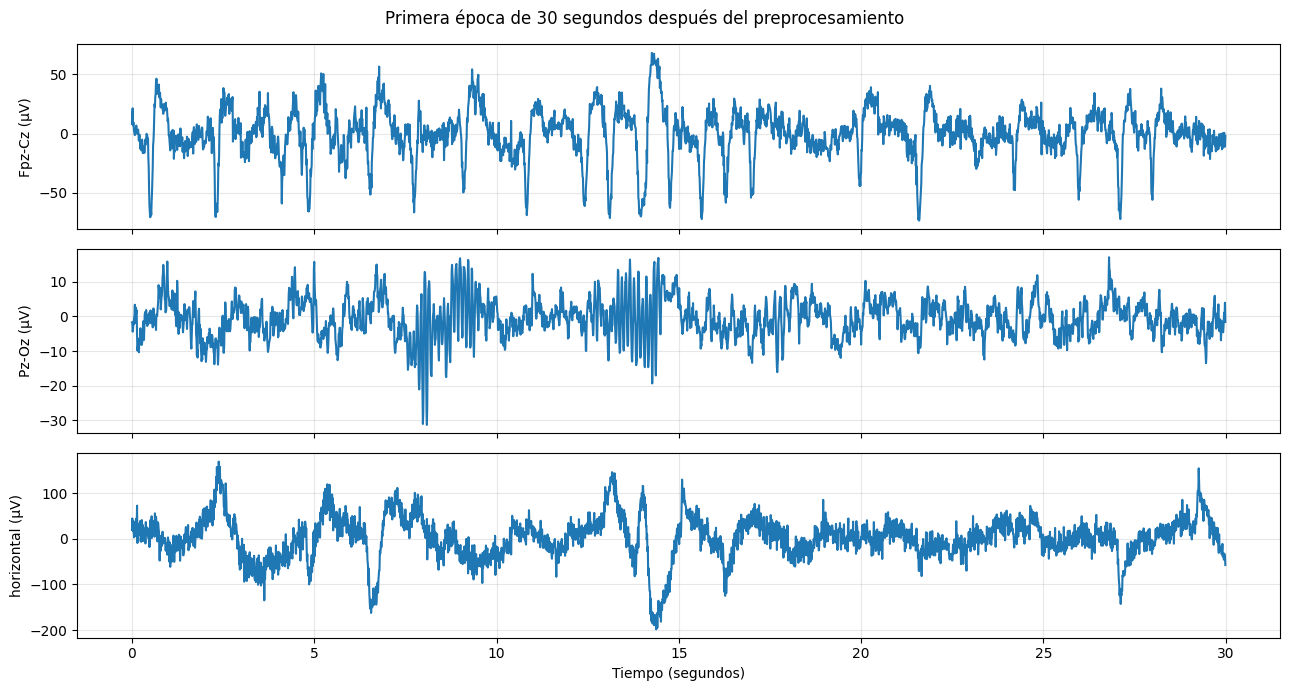

In [13]:
# Primera época del primer registro procesado
frecuencia = raw_prueba.info["sfreq"]
tiempo = np.arange(X_prueba.shape[2]) / frecuencia

fig, axes = plt.subplots(3, 1, figsize=(13, 7), sharex=True)
for i, ax in enumerate(axes):
    ax.plot(tiempo, X_prueba[0, i, :] * 1e6)
    ax.set_ylabel(canales[i] + " (µV)")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Tiempo (segundos)")
fig.suptitle("Primera época de 30 segundos después del preprocesamiento")
plt.tight_layout()
plt.show()

### **6.2. Hipnograma de las épocas que quedaron tras el preprocesamiento**

Este hipnograma muestra las **épocas conservadas en orden**, como secuencia de etiquetas `y`. A diferencia del hipnograma original, su eje horizontal cuenta las épocas guardadas y **no recupera los intervalos excluidos**. Esto permite verificar visualmente la secuencia que recibirá el modelo.

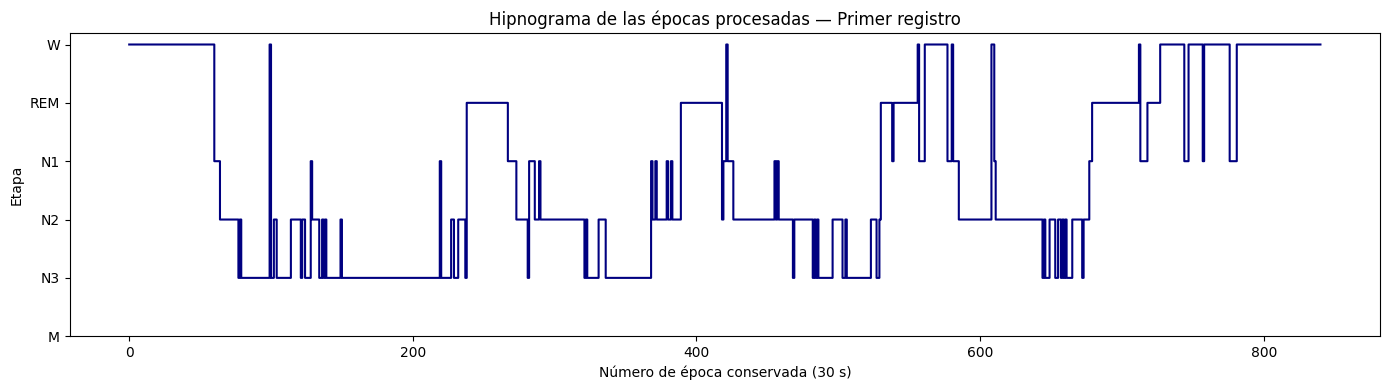

In [14]:
orden = ["W", "REM", "N1", "N2", "N3", "M"]
posiciones = {nombre: i for i, nombre in enumerate(orden)}

# Convertir cada código en una posición del gráfico
y_grafica = [posiciones[STAGE_NAMES[int(label)]] for label in y_prueba]

fig, ax = plt.subplots(figsize=(14, 4))
ax.step(np.arange(len(y_grafica)), y_grafica, where="post", color="navy")
ax.set_yticks(range(len(orden)))
ax.set_yticklabels(orden)
ax.invert_yaxis()
ax.set_xlabel("Número de época conservada (30 s)")
ax.set_ylabel("Etapa")
ax.set_title("Hipnograma de las épocas procesadas — Primer registro")
plt.tight_layout()
plt.show()

# **7. Procesar TODOS los registros y guardar los nuevos `.npz`**

Como eliminé la carpeta anterior de `.npz`, la vuelvo a crear con el **mismo nombre**: `SleepCassette_procesado`.

Se mantienen los archivos originales `.edf` de Drive. Cada archivo `.npz` contiene **`X`, `y` y `subj`**, igual que en mi proyecto original. Si ejecutas de nuevo esta celda y un `.npz` ya existe, se omite para no reprocesarlo innecesariamente.

In [15]:
# Carpeta de salida que tenía originalmente
PROC_DIR = Path("/content/drive/MyDrive/SleepCassette_procesado")
PROC_DIR.mkdir(parents=True, exist_ok=True)

print("Los nuevos archivos se guardarán en:", PROC_DIR)

resultados_procesamiento = []

for psg, hyp in tqdm(pares, desc="Procesando registros"):

    archivo_salida = PROC_DIR / f"{psg.stem}_epochs.npz"
    if archivo_salida.exists():
        print("Ya existe:", archivo_salida.name)
        continue

    # Preprocesar el registro
    X, y = preprocess_recording(psg, hyp)

    # Identificar el sujeto como en el código original
    id_sujeto = psg.name[:5]

    # Guardar señales, etiquetas e identificador
    np.savez_compressed(
        archivo_salida,
        X=X,
        y=y,
        subj=id_sujeto
    )

    resultados_procesamiento.append({
        "Registro": psg.name,
        "Sujeto": id_sujeto,
        "Épocas": len(y),
        "Dimensiones X": str(X.shape),
        "Movimiento (M)": int(np.sum(y == 6))
    })

    del X, y

# Mostrar resumen de los registros nuevos procesados en esta ejecución
if resultados_procesamiento:
    df_procesamiento = pd.DataFrame(resultados_procesamiento)
    display(df_procesamiento.head())
    print("Archivos nuevos:", len(df_procesamiento))
else:
    print("No se generaron archivos nuevos (puede que ya existieran).")

Los nuevos archivos se guardarán en: /content/drive/MyDrive/SleepCassette_procesado


Procesando registros:   0%|          | 0/153 [00:00<?, ?it/s]

Reading 0 ... 7949999  =      0.000 ... 79499.990 secs...
Reading 0 ... 8489999  =      0.000 ... 84899.990 secs...
Reading 0 ... 8405999  =      0.000 ... 84059.990 secs...
Reading 0 ... 8549999  =      0.000 ... 85499.990 secs...
Reading 0 ... 8411999  =      0.000 ... 84119.990 secs...
Reading 0 ... 8267999  =      0.000 ... 82679.990 secs...
Reading 0 ... 8459999  =      0.000 ... 84599.990 secs...
Reading 0 ... 8195999  =      0.000 ... 81959.990 secs...
Reading 0 ... 7709999  =      0.000 ... 77099.990 secs...
Reading 0 ... 8375999  =      0.000 ... 83759.990 secs...
Reading 0 ... 8165999  =      0.000 ... 81659.990 secs...
Reading 0 ... 8417999  =      0.000 ... 84179.990 secs...
Reading 0 ... 8309999  =      0.000 ... 83099.990 secs...
Reading 0 ... 8489999  =      0.000 ... 84899.990 secs...
Reading 0 ... 8429999  =      0.000 ... 84299.990 secs...
Reading 0 ... 8309999  =      0.000 ... 83099.990 secs...
Reading 0 ... 8387999  =      0.000 ... 83879.990 secs...
Reading 0 ... 

,Registro,Sujeto,Épocas,Dimensiones X,Movimiento (M)
0,SC4001E0-PSG.edf,SC400,841,"(841, 3, 3000)",0
1,SC4002E0-PSG.edf,SC400,1128,"(1128, 3, 3000)",1
2,SC4011E0-PSG.edf,SC401,1103,"(1103, 3, 3000)",0
3,SC4012E0-PSG.edf,SC401,1186,"(1186, 3, 3000)",0
4,SC4021E0-PSG.edf,SC402,1025,"(1025, 3, 3000)",0


Archivos nuevos: 153


## **8. Comprobar los archivos guardados y la distribución de TODOS los registros**

Es importante comprobar que los archivos se guardaron correctamente y que las etiquetas incluyen la nueva categoría **M** cuando existan anotaciones suficientemente largas.

In [16]:
archivos_npz = sorted(PROC_DIR.glob("*_epochs.npz"))
print("Archivos NPZ guardados:", len(archivos_npz))

if not archivos_npz:
    raise FileNotFoundError("No hay archivos .npz en la carpeta de salida.")

# Leer un ejemplo guardado en Drive
with np.load(archivos_npz[0], allow_pickle=False) as datos:
    X = datos["X"]
    y = datos["y"]
    subj = str(datos["subj"])

print("Primer archivo:", archivos_npz[0].name)
print("Sujeto:", subj)
print("Dimensiones X:", X.shape)
print("Dimensiones y:", y.shape)
print("¿Tres canales?", X.shape[1] == 3)
print("¿Una etiqueta por época?", len(X) == len(y))
print("¿Datos finitos?", np.isfinite(X).all())
print("Etiquetas encontradas:", np.unique(y))

Archivos NPZ guardados: 153
Primer archivo: SC4001E0-PSG_epochs.npz
Sujeto: SC400
Dimensiones X: (841, 3, 3000)
Dimensiones y: (841,)
¿Tres canales? True
¿Una etiqueta por época? True
¿Datos finitos? True
Etiquetas encontradas: [1 2 3 4 5]


Contando etiquetas:   0%|          | 0/153 [00:00<?, ?it/s]

,Etapa,Frecuencia,Porcentaje (%)
0,W,65941,33.71
1,N1,21522,11.00
2,N2,69132,35.34
3,N3,13039,6.67
4,REM,25835,13.21
5,M,128,0.07


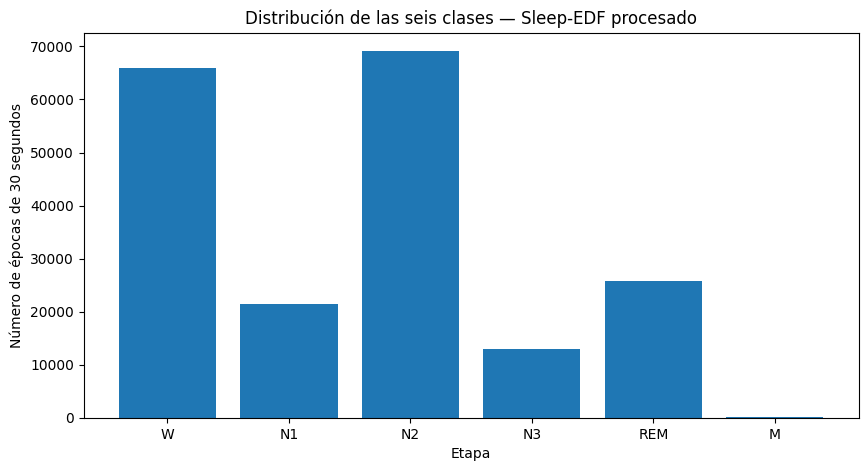

Total de épocas: 195597
Épocas de movimiento M: 128


In [17]:
# Contar las clases de todos los archivos .npz
conteos = np.zeros(6, dtype=int)

for archivo in tqdm(archivos_npz, desc="Contando etiquetas"):
    with np.load(archivo, allow_pickle=False) as datos:
        etiquetas = datos["y"]
    if not np.isin(etiquetas, [1, 2, 3, 4, 5, 6]).all():
        raise ValueError("Etiquetas inesperadas en " + archivo.name)
    conteos += np.bincount(etiquetas, minlength=7)[1:7]

df_distribucion = pd.DataFrame({
    "Etapa": list(STAGE_NAMES.values()),
    "Frecuencia": conteos
})
df_distribucion["Porcentaje (%)"] = (
    100 * df_distribucion["Frecuencia"] / max(1, conteos.sum())
).round(2)

display(df_distribucion)

plt.figure(figsize=(10, 5))
plt.bar(df_distribucion["Etapa"], df_distribucion["Frecuencia"])
plt.title("Distribución de las seis clases — Sleep-EDF procesado")
plt.xlabel("Etapa")
plt.ylabel("Número de épocas de 30 segundos")
plt.show()

print("Total de épocas:", conteos.sum())
print("Épocas de movimiento M:", conteos[5])
if conteos[5] == 0:
    print("ATENCIÓN: no se generaron épocas M de 30 segundos.")
    print("Revisar las duraciones de Movement time antes de entrenar 6 clases.")

# **9. Estadísticas de los archivos procesados (.npz)**

Estas estadísticas se calculan **a partir de los `.npz` nuevos guardados en Google Drive**, sin volver a leer los PSG/Hypnogram ni repetir el preprocesamiento.

Se obtienen tres tablas: **por registro**, **por sujeto** y **resumen general** (con las seis clases: W, N1, N2, N3, REM y M).

### **9.1. Estadísticas por registro**

Cada archivo `.npz` corresponde a un registro y contiene `X`, `y` y `subj`, como lo guardamos anteriormente. Contaremos las etiquetas y verificaremos las dimensiones de las señales.

> Si ya ejecutaste el preprocesamiento, **no vuelvas a correr el `for` que genera los `.npz`**. Basta con conectar Drive (sección 1) y ejecutar las celdas de esta sección 9.

In [18]:
# Leer los archivos .npz nuevos directamente desde Drive
PROC_DIR = Path("/content/drive/MyDrive/SleepCassette_procesado")
archivos_npz = sorted(PROC_DIR.glob("*_epochs.npz"))
print("Archivos procesados:", len(archivos_npz))

if not archivos_npz:
    raise FileNotFoundError("No se encontraron archivos .npz en " + str(PROC_DIR))

resumen_registros = []

for archivo in tqdm(archivos_npz, desc="Calculando estadísticas"):
    with np.load(archivo, allow_pickle=False) as datos:
        X = datos["X"]
        y = datos["y"]
        sujeto = str(datos["subj"])

    if X.shape[0] != len(y) or X.shape[1:] != (3, 3000):
        raise ValueError("Revisar dimensiones de " + archivo.name)
    if not np.isin(y, [1, 2, 3, 4, 5, 6]).all():
        raise ValueError("Revisar etiquetas de " + archivo.name)

    cantidades = np.bincount(y, minlength=7)

    resumen_registros.append({
        "Registro": archivo.name.replace("_epochs.npz", ".edf"),
        "Sujeto": sujeto,
        "Épocas": len(y),
        "Duración (h)": round(len(y) * 30 / 3600, 2),
        "Dimensiones X": str(X.shape),
        "Dimensiones y": str(y.shape),
        "W": int(cantidades[1]),
        "N1": int(cantidades[2]),
        "N2": int(cantidades[3]),
        "N3": int(cantidades[4]),
        "REM": int(cantidades[5]),
        "M": int(cantidades[6])
    })
    del X, y

df_registros = pd.DataFrame(resumen_registros)
display(df_registros.head(10))

Archivos procesados: 153


Calculando estadísticas:   0%|          | 0/153 [00:00<?, ?it/s]

,Registro,Sujeto,Épocas,Duración (h),Dimensiones X,Dimensiones y,W,N1,N2,N3,REM,M
0,SC4001E0-PSG.edf,SC400,841,7.01,"(841, 3, 3000)","(841,)",188,58,250,220,125,0
1,SC4002E0-PSG.edf,SC400,1128,9.40,"(1128, 3, 3000)","(1128,)",183,59,373,297,215,1
2,SC4011E0-PSG.edf,SC401,1103,9.19,"(1103, 3, 3000)","(1103,)",157,109,562,105,170,0
3,SC4012E0-PSG.edf,SC401,1186,9.88,"(1186, 3, 3000)","(1186,)",162,92,660,96,176,0
4,SC4021E0-PSG.edf,SC402,1025,8.54,"(1025, 3, 3000)","(1025,)",128,94,545,95,163,0
5,SC4022E0-PSG.edf,SC402,1010,8.42,"(1010, 3, 3000)","(1010,)",125,184,402,119,179,1
6,SC4031E0-PSG.edf,SC403,952,7.93,"(952, 3, 3000)","(952,)",140,61,485,57,209,0
7,SC4032E0-PSG.edf,SC403,911,7.59,"(911, 3, 3000)","(911,)",136,45,400,131,199,0
8,SC4041E0-PSG.edf,SC404,1236,10.30,"(1236, 3, 3000)","(1236,)",200,166,620,53,196,1
9,SC4042E0-PSG.edf,SC404,1204,10.03,"(1204, 3, 3000)","(1204,)",185,137,514,94,270,4


### **9.2. Estadísticas por sujeto**

Un mismo sujeto puede tener varios registros. Aquí **sumamos sus épocas** antes de calcular el porcentaje de cada etapa; así obtenemos una fila por sujeto, en lugar de una sola media general.

In [19]:
clases = ["W", "N1", "N2", "N3", "REM", "M"]

# Agrupar registros que pertenecen al mismo sujeto
df_sujetos = df_registros.groupby("Sujeto", as_index=False)[["Épocas"] + clases].sum()

# Número de registros por sujeto
df_sujetos.insert(1, "Registros", df_registros.groupby("Sujeto").size().values)
df_sujetos.insert(3, "Duración (h)", (df_sujetos["Épocas"] * 30 / 3600).round(2))

# Porcentaje de cada clase dentro de cada sujeto
for clase in clases:
    df_sujetos[clase + " (%)"] = (
        100 * df_sujetos[clase] / df_sujetos["Épocas"]
    ).round(2)

display(df_sujetos.head(10))
print("Sujetos diferentes:", len(df_sujetos))

,Sujeto,Registros,Épocas,Duración (h),W,N1,N2,N3,REM,M,W (%),N1 (%),N2 (%),N3 (%),REM (%),M (%)
0,SC400,2,1969,16.41,371,117,623,517,340,1,18.84,5.94,31.64,26.26,17.27,0.05
1,SC401,2,2289,19.08,319,201,1222,201,346,0,13.94,8.78,53.39,8.78,15.12,0.00
2,SC402,2,2035,16.96,253,278,947,214,342,1,12.43,13.66,46.54,10.52,16.81,0.05
3,SC403,2,1863,15.52,276,106,885,188,408,0,14.81,5.69,47.50,10.09,21.90,0.00
4,SC404,2,2440,20.33,385,303,1134,147,466,5,15.78,12.42,46.48,6.02,19.10,0.20
5,SC405,2,1920,16.00,430,158,833,249,248,2,22.40,8.23,43.39,12.97,12.92,0.10
6,SC406,2,1859,15.49,335,146,824,265,289,0,18.02,7.85,44.32,14.25,15.55,0.00
7,SC407,2,2249,18.74,531,173,795,384,366,0,23.61,7.69,35.35,17.07,16.27,0.00
8,SC408,2,2188,18.23,467,107,591,632,391,0,21.34,4.89,27.01,28.88,17.87,0.00
9,SC409,2,2259,18.82,289,100,1073,277,497,23,12.79,4.43,47.50,12.26,22.00,1.02


Sujetos diferentes: 78


### **9.3. Resumen general**

El **porcentaje global** considera todas las épocas reunidas. El **porcentaje promedio por sujeto** da el mismo peso a cada sujeto, aunque unos tengan más épocas que otros; por eso pueden diferir.

In [20]:
# Estadísticas generales sobre sujetos y registros
df_resumen = pd.DataFrame({
    "Estadística": [
        "Registros totales", "Sujetos totales", "Épocas totales",
        "Horas totales de épocas", "Promedio de épocas por sujeto",
        "Desviación estándar de épocas por sujeto", "Promedio de horas por sujeto"
    ],
    "Valor": [
        len(df_registros),
        len(df_sujetos),
        int(df_sujetos["Épocas"].sum()),
        round(df_sujetos["Épocas"].sum() * 30 / 3600, 2),
        round(df_sujetos["Épocas"].mean(), 2),
        round(df_sujetos["Épocas"].std(), 2),
        round(df_sujetos["Épocas"].mean() * 30 / 3600, 2)
    ]
})

# Distribución general de las seis clases
total_epocas = df_sujetos["Épocas"].sum()
df_general = pd.DataFrame({
    "Etapa": clases,
    "Épocas totales": [int(df_sujetos[c].sum()) for c in clases],
    "Porcentaje global (%)": [
        round(100 * df_sujetos[c].sum() / total_epocas, 2) for c in clases
    ],
    "Promedio por sujeto (%)": [
        round(df_sujetos[c + " (%)"].mean(), 2) for c in clases
    ],
    "Desv. estándar por sujeto (%)": [
        round(df_sujetos[c + " (%)"].std(), 2) for c in clases
    ]
})

print("RESUMEN GENERAL")
display(df_resumen)
print("DISTRIBUCIÓN DE ETAPAS")
display(df_general)

RESUMEN GENERAL


,Estadística,Valor
0,Registros totales,153.00
1,Sujetos totales,78.00
2,Épocas totales,195597.00
3,Horas totales de épocas,1629.98
4,Promedio de épocas por sujeto,2507.65
5,Desviación estándar de épocas por sujeto,743.77
6,Promedio de horas por sujeto,20.90


DISTRIBUCIÓN DE ETAPAS


,Etapa,Épocas totales,Porcentaje global (%),Promedio por sujeto (%),Desv. estándar por sujeto (%)
0,W,65941,33.71,30.34,13.65
1,N1,21522,11.00,10.91,5.80
2,N2,69132,35.34,37.51,10.06
3,N3,13039,6.67,7.35,6.99
4,REM,25835,13.21,13.83,4.81
5,M,128,0.07,0.06,0.14


### **9.4. Guardar las estadísticas en un Excel**

El archivo se guardará en la misma carpeta de Drive que contiene los `.npz`, con tres hojas: **Por registro**, **Por sujeto** y **Resumen general**.

In [21]:
archivo_excel = PROC_DIR / "estadisticas_sleep_edf_6_clases.xlsx"

with pd.ExcelWriter(archivo_excel) as excel:
    df_registros.to_excel(excel, sheet_name="Por registro", index=False)
    df_sujetos.to_excel(excel, sheet_name="Por sujeto", index=False)
    df_resumen.to_excel(excel, sheet_name="Resumen general", index=False)
    df_general.to_excel(
        excel, sheet_name="Resumen general", index=False,
        startrow=len(df_resumen) + 3
    )

print("Excel guardado en:", archivo_excel)

Excel guardado en: /content/drive/MyDrive/SleepCassette_procesado/estadisticas_sleep_edf_6_clases.xlsx
